# 02. Queue-Reactive & State-Dependent Hawkes Stylized Facts, Empirical LOBSTER Calibration & Ogata Goodness-of-Fit

**Repository**: `queue-reactive-book`  
**References**:
- Huang, W., Lehalle, C.-A., & Rosenbaum, M. (2015). *Simulating and analyzing order book data: The queue-reactive model*. **JASA**, 110(509), 107-122.
- Wu, P., Rambaldi, M., Muzy, J.-F., & Bacry, E. (2019). *Queue-reactive Hawkes models for the order flow*. **arXiv:1901.08938**.
- Bodor, H., & Carlier, L. (2024). *The Queue-Reactive Model: Structural Properties, Empirical Foundations, and Extensions*. **arXiv:2405.18594**.
- Noble, S., Rosenbaum, M., & Souilmi, O. (2026). *Queue-Reactive Limit Order Book Simulation: An Empirical Intensity Table Approach*. **arXiv:2603.24137**.

---

## Executive Summary

In this notebook, we bridge the empirical L2/L3 datasets curated in `data/` (`LOBSTER` 2012-06-21 5-level message and orderbook files for `AAPL`, `AMZN`, `GOOG`, `INTC`, `MSFT`, and `FI-2010`) with the C++20 `sim::QueueReactiveProcess` engine:
1. **Empirical LOBSTER Calibration**: We inspect the calibrated HLR curves, level-specific Median Event Sizes (MES), and the 525-cell (`21 x 5 x 5`) Noble-Rosenbaum (2026) 3D intensity surface (`data/hlr_calibrated_5level.json` & `.csv`).
2. **Birth-Death Stationary Invariant Queue Distribution (`Theorem 2.1`, HLR 2015)**: We compare the analytical birth-death invariant distribution $\pi_i(n) \propto \prod_{k=1}^n \frac{\lambda_i^L(k-1)}{\lambda_i^C(k) + \lambda_i^M(k)}$ (with ergodic damping $\theta_{\text{ergodic}} > 0$) against simulated L1 queue depth histograms.
3. **Ogata's Time-Rescaling Theorem Goodness-of-Fit**: Under exact Ogata thinning (`next_event_ogata_thinning`), the integrated conditional intensities $\tau_k = \int_{t_{k-1}}^{t_k} \Lambda(s)\,\mathrm{d}s$ must follow a unit-rate exponential distribution $\text{Exp}(1)$. We verify this via Q-Q plots and the Kolmogorov-Smirnov test.
4. **Microstructure Stylized Facts**: Signature plot (realized volatility vs sampling horizon) and trade-sign / order-flow autocorrelation decay.


In [1]:
import sys
import json
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(pathlib.Path.cwd()))
import qrlob_notebook_utils as qru

qru.apply_publication_style()

calib_path = qru.DATA_DIR / "hlr_calibrated_5level.json"
calib_data = json.loads(calib_path.read_text(encoding="ascii"))
print("Loaded calibrated HLR + Noble-Rosenbaum 3D parameters from:", calib_path.name)
print("Tickers calibrated:", list(calib_data["ticker_summaries"].keys()))
print("Total empirical events:", calib_data["total_events_calibrated"])


Loaded calibrated HLR + Noble-Rosenbaum 3D parameters from: hlr_calibrated_5level.json
Tickers calibrated: ['AAPL', 'AMZN', 'GOOG', 'INTC', 'MSFT']
Total empirical events: 50000


## 1. Empirical LOBSTER 5-Level Summary & Noble-Rosenbaum (2026) 3D Intensity Surface

Let us examine the per-ticker calibration summary (`AAPL`, `AMZN`, `GOOG`, `INTC`, `MSFT`) and visualize the calibrated 3D intensity surface $\lambda^e(I_t, S_t, Q_t)$ across the 21 L1 imbalance bins $I_t \in [-1, +1]$ (including the exact zero point $\{0.0\}$).


In [2]:
ticker_rows = []
for tk, info in calib_data["ticker_summaries"].items():
    ev_c = info["event_counts"]
    tot_ev = info["rows_analyzed"]
    span_s = info["time_span_seconds"]
    ticker_rows.append({
        "Ticker": tk,
        "Events": tot_ev,
        "Horizon (s)": round(span_s, 1),
        "Empirical Rate (ev/s)": round(tot_ev / max(1e-9, span_s), 2),
        "Mean Spread (ticks)": round(info["mean_spread_ticks"], 2),
        "Mean L1 Imbalance": round(info["mean_imbalance_l1"], 4),
        "Add %": round(100.0 * ev_c["add"] / tot_ev, 1),
        "Cancel %": round(100.0 * ev_c["cancel"] / tot_ev, 1),
        "Exec %": round(100.0 * ev_c["exec"] / tot_ev, 1),
    })
display(pd.DataFrame(ticker_rows))

table_csv = qru.DATA_DIR / "hlr_calibrated_5level.csv"
df_3d = pd.read_csv(table_csv)
print(f"3D Empirical Table shape: {df_3d.shape[0]} cells (21 imbalance x 5 spread x 5 depth bins)")
display(df_3d.head(8))


,Ticker,Events,Horizon (s),Empirical Rate (ev/s),Mean Spread (ticks),Mean L1 Imbalance,Add %,Cancel %,Exec %
0,AAPL,10000,435.1,22.98,28.49,-0.0531,46.2,41.2,12.6
1,AMZN,10000,1437.1,6.96,23.45,0.1099,48.7,43.8,7.5
2,GOOG,10000,1596.1,6.27,53.98,-0.0778,48.5,44.5,7.1
3,INTC,10000,82.7,120.91,1.69,0.1619,48.9,43.9,7.2
4,MSFT,10000,247.5,40.41,1.44,-0.0628,48.4,40.2,11.4


3D Empirical Table shape: 525 cells (21 imbalance x 5 spread x 5 depth bins)


,imbalance_bin,imbalance_center,spread_bin,spread_ticks,depth_bin,sample_count,lambda_add_per_us,lambda_cancel_per_us,lambda_exec_per_us,lambda_create_per_us
0,0,-1.0,0,1,0,0,0.047020,0.054857,0.026122,0.000000
1,0,-1.0,0,1,1,0,0.053799,0.063513,0.029888,0.000000
2,0,-1.0,0,1,2,1,0.060509,0.072275,0.033616,0.000000
3,0,-1.0,0,1,3,16,0.092430,0.026409,0.011884,0.006602
4,0,-1.0,0,1,4,439,0.000874,0.000662,0.000274,0.000189
5,0,-1.0,1,2,0,1,0.043472,0.050717,0.024151,0.009660
6,0,-1.0,1,2,1,4,0.049758,0.058742,0.027643,0.011057
7,0,-1.0,1,2,2,1,0.055985,0.066871,0.031103,0.012441


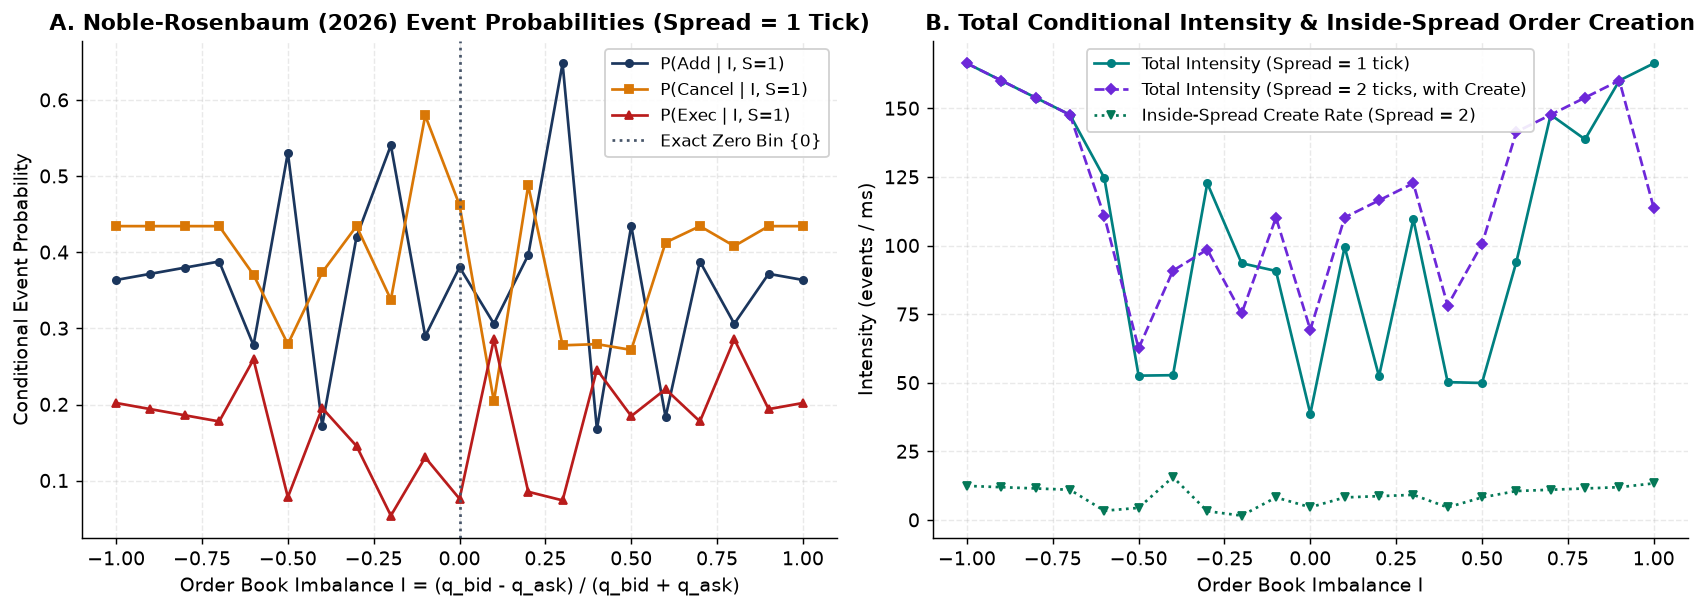

In [3]:
# Plot Noble-Rosenbaum (2026) 3D Conditional Event Probabilities & Total Intensity vs Imbalance
sub_s0_d2 = df_3d[(df_3d["spread_bin"] == 0) & (df_3d["depth_bin"] == 2)].sort_values("imbalance_bin")
sub_s1_d2 = df_3d[(df_3d["spread_bin"] == 1) & (df_3d["depth_bin"] == 2)].sort_values("imbalance_bin")
imb_centers = sub_s0_d2["imbalance_center"].values

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.2, 4.8))

tot_s0 = np.maximum(1e-12, (
    sub_s0_d2["lambda_add_per_us"] + sub_s0_d2["lambda_cancel_per_us"] +
    sub_s0_d2["lambda_exec_per_us"] + sub_s0_d2["lambda_create_per_us"]
).values)
ax1.plot(imb_centers, sub_s0_d2["lambda_add_per_us"].values / tot_s0, "-o", markersize=4,
         color=qru.PALETTE["navy"], label="P(Add | I, S=1)")
ax1.plot(imb_centers, sub_s0_d2["lambda_cancel_per_us"].values / tot_s0, "-s", markersize=4,
         color=qru.PALETTE["amber"], label="P(Cancel | I, S=1)")
ax1.plot(imb_centers, sub_s0_d2["lambda_exec_per_us"].values / tot_s0, "-^", markersize=4,
         color=qru.PALETTE["crimson"], label="P(Exec | I, S=1)")
ax1.axvline(0.0, color=qru.PALETTE["slate"], linestyle=":", label="Exact Zero Bin {0}")
ax1.set_xlabel("Order Book Imbalance I = (q_bid - q_ask) / (q_bid + q_ask)")
ax1.set_ylabel("Conditional Event Probability")
ax1.set_title("A. Noble-Rosenbaum (2026) Event Probabilities (Spread = 1 Tick)")
ax1.legend()

tot_s1 = np.maximum(1e-12, (
    sub_s1_d2["lambda_add_per_us"] + sub_s1_d2["lambda_cancel_per_us"] +
    sub_s1_d2["lambda_exec_per_us"] + sub_s1_d2["lambda_create_per_us"]
).values)
ax2.plot(imb_centers, tot_s0 * 1e3, "-o", markersize=4, color=qru.PALETTE["teal"],
         label="Total Intensity (Spread = 1 tick)")
ax2.plot(imb_centers, tot_s1 * 1e3, "--D", markersize=4, color=qru.PALETTE["purple"],
         label="Total Intensity (Spread = 2 ticks, with Create)")
ax2.plot(imb_centers, sub_s1_d2["lambda_create_per_us"].values * 1e3, ":v", markersize=4,
         color=qru.PALETTE["emerald"], label="Inside-Spread Create Rate (Spread = 2)")
ax2.set_xlabel("Order Book Imbalance I")
ax2.set_ylabel("Intensity (events / ms)")
ax2.set_title("B. Total Conditional Intensity & Inside-Spread Order Creation")
ax2.legend()

plt.tight_layout()
fig_path1 = qru.FIG_DIR / "fig02_noble_rosenbaum_3d_surface.png"
plt.savefig(fig_path1, bbox_inches="tight")
plt.show()


## 2. Multi-Level Queue-Reactive + Hawkes Trajectory & Ogata Time-Rescaling Goodness-of-Fit

We now simulate `15,000` L3 order-book events using `qrlob_ffi_simulate_qr_trajectory` with:
- 5-level HLR Model IIb/III queue-reactive intensities + 6x6 Hawkes self/cross-excitation (`hawkes_scale = 0.01`),
- Inside-spread order creation and reference-price shifts (`theta_reprice = 0.65`),
- Exact Ogata thinning (`use_ogata_thinning = True`), recording the integrated conditional intensity residuals $\tau_k = \int_{t_{k-1}}^{t_k} \Lambda(s)\,\mathrm{d}s$.


In [4]:
df_qr = qru.simulate_qr_dataframe(
    num_events=15000,
    seed=20260621,
    use_3d_table=False,
    use_ogata_thinning=True,
    theta_ergodic=0.03,
    theta_reprice=0.65,
)
print(f"Simulated {len(df_qr)} multi-level QR+Hawkes events.")
display(df_qr.head(6))

residuals = df_qr["ogata_residual"].values
residuals = residuals[residuals > 0]
ks_d, ks_pval = qru.ks_statistic_exp1(residuals)
print(f"Ogata Residuals Summary: N={len(residuals)}, Mean={residuals.mean():.4f} (theoretical=1.0000), "
      f"Std={residuals.std():.4f} (theoretical=1.0000)")
print(f"Kolmogorov-Smirnov Test vs Exp(1): D = {ks_d:.4f}, p-value = {ks_pval:.4f}")
assert 0.90 <= residuals.mean() <= 1.10, "Ogata residual mean out of theoretical [0.90, 1.10] band!"


Simulated 15000 multi-level QR+Hawkes events.


,step,time_ns,best_bid,best_ask,mid,spread,bid_vol_l1,ask_vol_l1,total_bid_vol_5,total_ask_vol_5,event_kind,event_level,event_side,event_qty,price_shift,total_intensity,ogata_residual
0,0,128,99,101,100.0,2,100,100,500,500,3,1,-1,21,0,0.511220,0.192691
1,1,2359,99,102,100.5,3,100,100,500,400,3,4,-1,13,0,0.511434,3.320824
2,2,2399,99,102,100.5,3,100,100,500,300,2,2,1,7,0,0.513348,0.056847
3,3,5084,99,102,100.5,3,100,100,400,300,3,2,-1,54,0,0.511501,3.380478
4,4,7644,99,102,100.5,3,100,100,400,200,2,5,1,510,0,0.511396,2.838466
5,5,8063,99,102,100.5,3,100,100,300,200,0,3,1,41,0,0.510651,0.439612


Ogata Residuals Summary: N=15000, Mean=1.0136 (theoretical=1.0000), Std=1.0237 (theoretical=1.0000)
Kolmogorov-Smirnov Test vs Exp(1): D = 0.0067, p-value = 0.5075


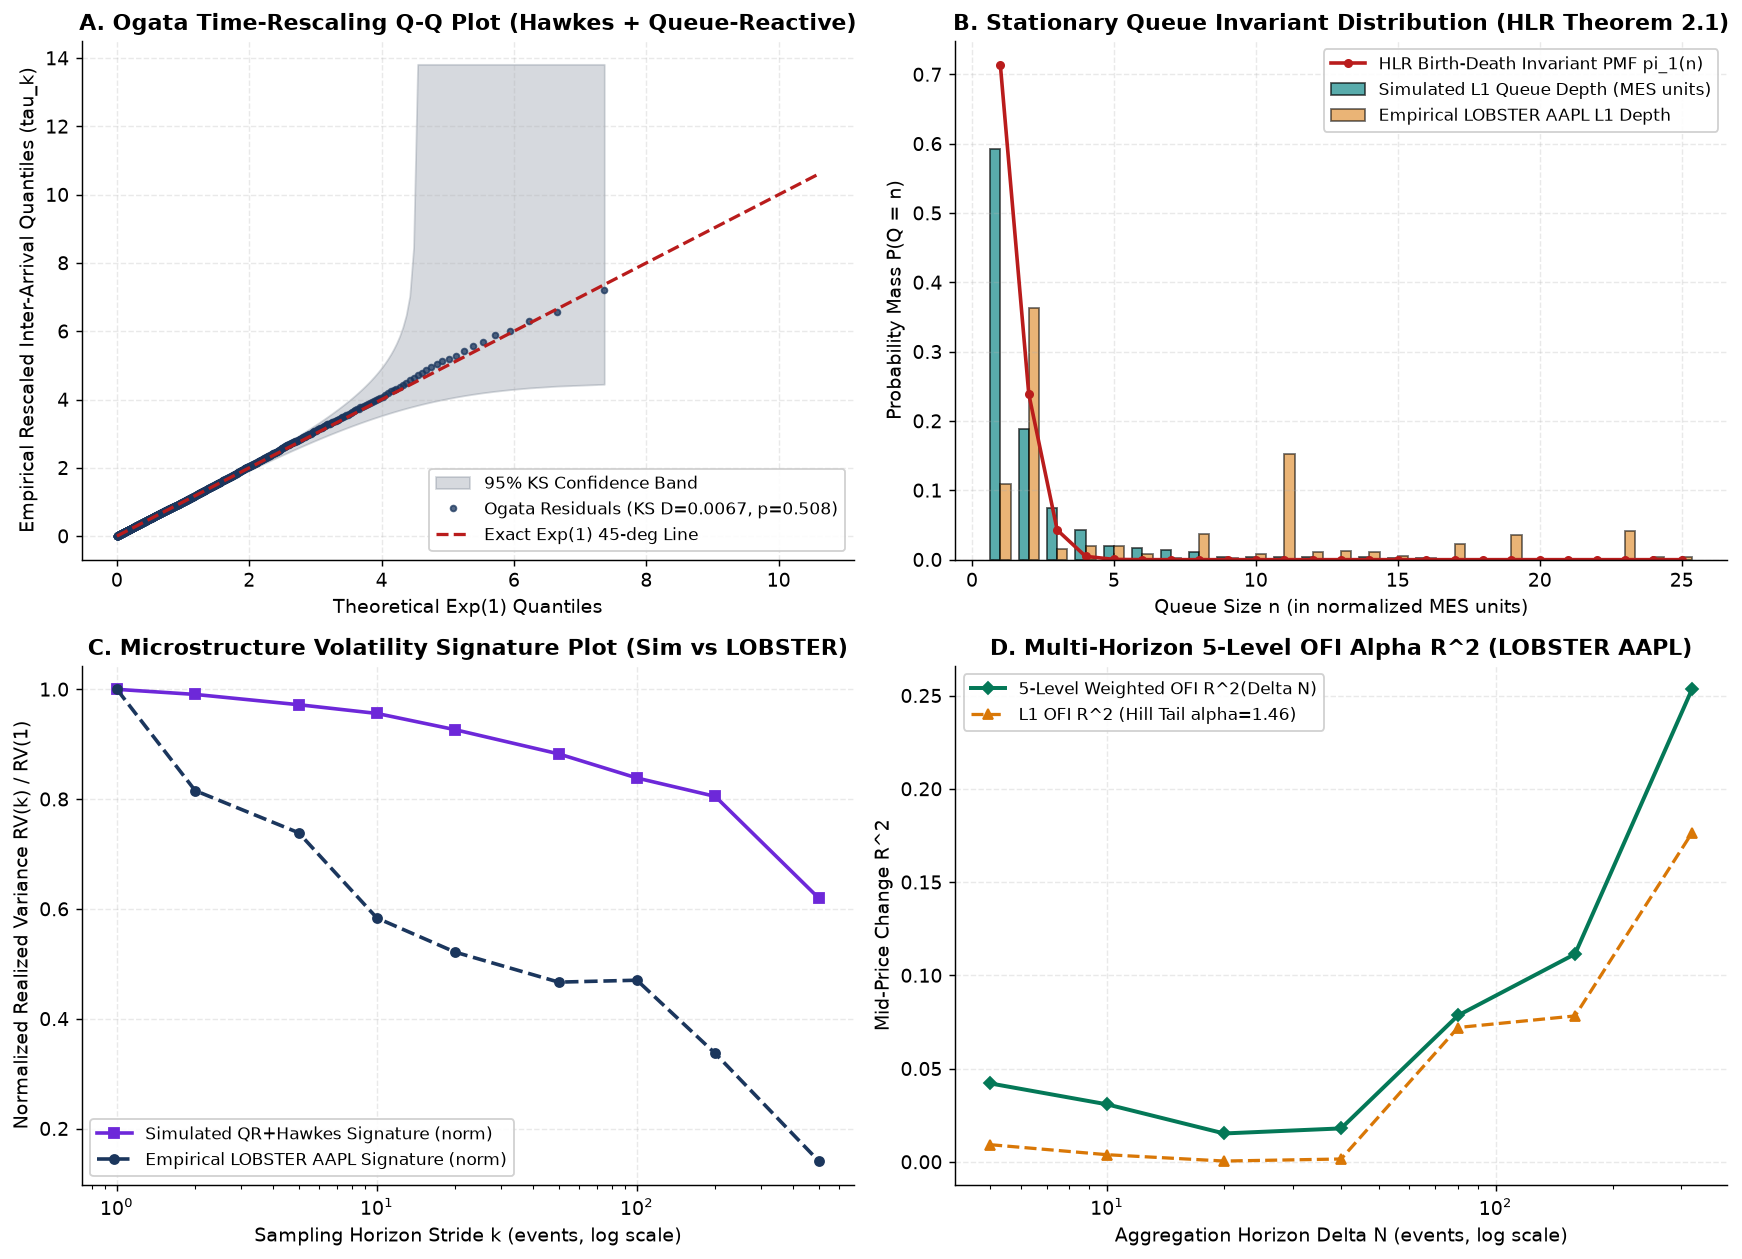

Saved figure to: /home/radu/code/queue-reactive-book/notebooks/figures/fig02_stylized_facts_and_ogata.png


In [5]:
# 4-Panel Stylized Facts & Goodness-of-Fit Figure:
# Panel A: Ogata Q-Q Plot against Exp(1) with 95% KS Confidence Bands
# Panel B: Analytical Birth-Death Stationary Queue PMF vs Empirical LOBSTER AAPL & Simulated Queue Depth
# Panel C: Microstructure Signature Plot (Realized Volatility vs Sampling Stride)
# Panel D: Multi-Horizon 5-Level OFI Return Predictability R^2(Delta N) & Log-Return Hill Tail Index
fig, axes = plt.subplots(2, 2, figsize=(13.5, 9.8))

# Panel A: Ogata Q-Q plot with 95% confidence bands
ax = axes[0, 0]
sorted_res = np.sort(residuals)
n_res = len(sorted_res)
probs = (np.arange(1, n_res + 1) - 0.5) / n_res
theo_quantiles = -np.log(1.0 - probs)
ks_band = 1.358 / np.sqrt(n_res)
q_lo = -np.log(np.clip(1.0 - np.clip(probs - ks_band, 1e-6, 1.0 - 1e-6), 1e-6, 1.0))
q_hi = -np.log(np.clip(1.0 - np.clip(probs + ks_band, 1e-6, 1.0 - 1e-6), 1e-6, 1.0))
ax.fill_between(theo_quantiles[::10], q_lo[::10], q_hi[::10], color=qru.PALETTE["slate"], alpha=0.22,
                label="95% KS Confidence Band")
ax.plot(theo_quantiles[::10], sorted_res[::10], "o", markersize=3.2, alpha=0.75,
        color=qru.PALETTE["navy"], label=f"Ogata Residuals (KS D={ks_d:.4f}, p={ks_pval:.3f})")
max_q = max(theo_quantiles.max(), sorted_res.max())
ax.plot([0, max_q], [0, max_q], "--", color=qru.PALETTE["crimson"], linewidth=1.8, label="Exact Exp(1) 45-deg Line")
ax.set_xlabel("Theoretical Exp(1) Quantiles")
ax.set_ylabel("Empirical Rescaled Inter-Arrival Quantiles (tau_k)")
ax.set_title("A. Ogata Time-Rescaling Q-Q Plot (Hawkes + Queue-Reactive)")
ax.legend()

# Panel B: Analytical Birth-Death Stationary Invariant PMF vs Simulated & Real LOBSTER AAPL L1 Depth
ax = axes[0, 1]
pmf = qru.get_stationary_queue_pmf(64)
units_x = np.arange(1, 65)
sim_units = np.clip(np.round(df_qr["bid_vol_l1"].values / 20.0), 1, 64)
hist_vals, _ = np.histogram(sim_units, bins=np.arange(0.5, 65.5, 1.0), density=True)

ob_cols = []
for m in range(1, 6):
    ob_cols.extend([f"ask_p{m}", f"ask_q{m}", f"bid_p{m}", f"bid_q{m}"])
df_aapl_ob = pd.read_csv(qru.DATA_DIR / "lobster_AAPL_2012-06-21_orderbook_5.csv", names=ob_cols)
emp_mes = max(1.0, float(np.median(df_aapl_ob["bid_q1"].values)) / 4.0)
emp_units = np.clip(np.round(df_aapl_ob["bid_q1"].values / emp_mes), 1, 64)
emp_hist, _ = np.histogram(emp_units, bins=np.arange(0.5, 65.5, 1.0), density=True)

ax.bar(units_x[:25] - 0.18, hist_vals[:25], width=0.36, alpha=0.65, color=qru.PALETTE["teal"],
       edgecolor="black", label="Simulated L1 Queue Depth (MES units)")
ax.bar(units_x[:25] + 0.18, emp_hist[:25], width=0.36, alpha=0.55, color=qru.PALETTE["amber"],
       edgecolor="black", label="Empirical LOBSTER AAPL L1 Depth")
ax.plot(units_x[:25], pmf[:25], "-o", markersize=4, linewidth=2.0, color=qru.PALETTE["crimson"],
        label="HLR Birth-Death Invariant PMF pi_1(n)")
ax.set_xlabel("Queue Size n (in normalized MES units)")
ax.set_ylabel("Probability Mass P(Q = n)")
ax.set_title("B. Stationary Queue Invariant Distribution (HLR Theorem 2.1)")
ax.legend()

# Panel C: Microstructure Volatility Signature Plot (Simulated vs Empirical LOBSTER AAPL)
ax = axes[1, 0]
strides = [1, 2, 5, 10, 20, 50, 100, 200, 500]
mid_series = df_qr["mid"].values
emp_mid = 0.5 * (df_aapl_ob["ask_p1"].values + df_aapl_ob["bid_p1"].values) / 100.0
rv_sim = [np.mean((mid_series[k:] - mid_series[:-k]) ** 2) / k for k in strides]
rv_emp = [np.mean((emp_mid[k:] - emp_mid[:-k]) ** 2) / k for k in strides]
ax.plot(strides, rv_sim / max(1e-12, rv_sim[0]), "-s", color=qru.PALETTE["purple"], linewidth=2.0, markersize=5,
        label="Simulated QR+Hawkes Signature (norm)")
ax.plot(strides, rv_emp / max(1e-12, rv_emp[0]), "--o", color=qru.PALETTE["navy"], linewidth=2.0, markersize=5,
        label="Empirical LOBSTER AAPL Signature (norm)")
ax.set_xscale("log")
ax.set_xlabel("Sampling Horizon Stride k (events, log scale)")
ax.set_ylabel("Normalized Realized Variance RV(k) / RV(1)")
ax.set_title("C. Microstructure Volatility Signature Plot (Sim vs LOBSTER)")
ax.legend()

# Panel D: Multi-Horizon 5-Level OFI Return R^2 Decay & Hill Tail Estimator on LOBSTER AAPL
ax = axes[1, 1]
horizons = [5, 10, 20, 40, 80, 160, 320]
ofi_l1 = np.diff(df_aapl_ob["bid_q1"].values.astype(float)) - np.diff(df_aapl_ob["ask_q1"].values.astype(float))
ofi_5lvl = np.zeros_like(ofi_l1)
weights = [1.0, 0.7, 0.5, 0.35, 0.25]
for m, w in enumerate(weights, start=1):
    db = np.diff(df_aapl_ob[f"bid_q{m}"].values.astype(float))
    da = np.diff(df_aapl_ob[f"ask_q{m}"].values.astype(float))
    ofi_5lvl += w * (db - da)

r2_l1 = []
r2_5lvl = []
for h in horizons:
    c_l1 = np.convolve(ofi_l1, np.ones(h), mode="valid")
    c_5 = np.convolve(ofi_5lvl, np.ones(h), mode="valid")
    dm = emp_mid[h:] - emp_mid[:-h]
    corr1 = np.corrcoef(c_l1, dm)[0, 1]
    corr5 = np.corrcoef(c_5, dm)[0, 1]
    r2_l1.append(float(corr1 ** 2))
    r2_5lvl.append(float(corr5 ** 2))

abs_ret = np.sort(np.abs(np.diff(emp_mid))[np.abs(np.diff(emp_mid)) > 0])[::-1]
k_hill = max(10, int(0.10 * len(abs_ret)))
hill_alpha = 1.0 / max(1e-9, float(np.mean(np.log(abs_ret[:k_hill] / abs_ret[k_hill]))))

ax.plot(horizons, r2_5lvl, "-D", color=qru.PALETTE["emerald"], linewidth=2.2, markersize=5,
        label="5-Level Weighted OFI R^2(Delta N)")
ax.plot(horizons, r2_l1, "--^", color=qru.PALETTE["amber"], linewidth=1.8, markersize=5,
        label=f"L1 OFI R^2 (Hill Tail alpha={hill_alpha:.2f})")
ax.set_xscale("log")
ax.set_xlabel("Aggregation Horizon Delta N (events, log scale)")
ax.set_ylabel("Mid-Price Change R^2")
ax.set_title("D. Multi-Horizon 5-Level OFI Alpha R^2 (LOBSTER AAPL)")
ax.legend()

plt.tight_layout()
fig_path2 = qru.FIG_DIR / "fig02_stylized_facts_and_ogata.png"
plt.savefig(fig_path2, bbox_inches="tight")
plt.show()
print("Saved figure to:", fig_path2)


## 3. Exact $O(N)$ Ozaki + Queue-Reactive Hawkes Maximum Likelihood Estimation (`calibrate_mle`)

We now calibrate the state-dependent Queue-Reactive Hawkes conditional intensity
$$\lambda(t_k^-) = \mu \phi(q_k; \gamma_{\text{qr}}) + \alpha R(k), \qquad \phi(q_k; \gamma_{\text{qr}}) = \frac{1}{1 + \gamma_{\text{qr}}(q_k / \bar{q})},$$
across all 5 paired LOBSTER Level-5 datasets (`AAPL`, `AMZN`, `GOOG`, `INTC`, `MSFT`) using `qrlob_ffi_calibrate_lobster_mle` (70% training split, 30% out-of-sample test split), co-reading the companion `_orderbook_5.csv` pre-event resting L1 depth.

In [6]:
mle_rows = []
for tk in ["AAPL", "AMZN", "GOOG", "INTC", "MSFT"]:
    csv_p = str(qru.DATA_DIR / f"lobster_{tk}_2012-06-21_message_5.csv")
    rep, oos_res = qru.calibrate_lobster_mle_ffi(csv_p, train_fraction=0.70)
    assert rep["oos_llr_per_event"] > 0.0, f"Expected positive OOS LLR for {tk}"
    mle_rows.append({
        "Ticker": tk,
        "Mean Resting Q1": round(rep["mean_queue_depth"], 1),
        "mu (Hz)": f"{rep['mu_hz']:.2f} +/- {rep['se_mu']:.2f}",
        "alpha (Hz)": f"{rep['alpha_hz']:.1f} +/- {rep['se_alpha']:.1f}",
        "beta (Hz)": f"{rep['beta_hz']:.1f} +/- {rep['se_beta']:.1f}",
        "Branching n_hat": round(rep["branching_ratio"], 4),
        "gamma_qr": round(rep["gamma_qr"], 4),
        "Train LL (Hawkes)": round(rep["log_likelihood_train"], 1),
        "Train LL (Poisson)": round(rep["log_likelihood_poisson_train"], 1),
        "OOS LLR / Event": round(rep["oos_llr_per_event"], 4),
        "OOS KS D": round(rep["ks_statistic"], 4),
        "VPIN": round(rep["vpin"], 4),
    })
df_mle = pd.DataFrame(mle_rows)
display(df_mle)


,Ticker,Mean Resting Q1,mu (Hz),alpha (Hz),beta (Hz),Branching n_hat,gamma_qr,Train LL (Hawkes),Train LL (Poisson),OOS LLR / Event,OOS KS D,VPIN
0,AAPL,111.7,6.05 +/- 0.30,3722.6 +/- 120.0,5381.6 +/- 148.9,0.6917,0.0000,7486.6,2789.5,2.5602,0.1460,0.7584
1,AMZN,123.4,1.91 +/- 0.09,615.6 +/- 20.9,970.6 +/- 31.1,0.6343,0.0163,4510.6,889.7,3.9416,0.3460,0.6367
2,GOOG,217.5,1.72 +/- 0.09,502.4 +/- 15.9,691.9 +/- 20.7,0.7261,0.0000,5371.6,1167.9,3.3127,0.2296,0.6301
3,INTC,767.7,21.89 +/- 1.34,3999.0 +/- 120.8,5029.1 +/- 132.6,0.7952,0.0000,9357.0,5150.2,4.6106,0.1493,0.7764
4,MSFT,4381.8,9.82 +/- 0.50,2268.4 +/- 72.7,3204.4 +/- 99.4,0.7079,0.0000,7661.4,3534.8,4.0751,0.1493,0.8383
